# Praktikum 5 : recall dan waktu pencarian ANN

In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Dataset random sesuai modul
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
features = ['latitude', 'longitude', 'rating', 'review_count', 'price_min']
df[features] = df[features].fillna(df[features].mean())
d = len(features)
nb = len(df)
nq = len(df)
k = 10
np.random.seed(42)
xb = df[features].to_numpy(dtype='float32')
xq = xb.copy()
faiss.omp_set_num_threads(4)

# Ground truth dengan FAISS brute force
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
_, gt_idx = index_flat.search(xq, k)

def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

results = {'Annoy': [], 'Faiss': [], 'HNSW': []}
rows = []

In [2]:
# Index dibuat sekali karena yang diukur hanya waktu query.
index_annoy = AnnoyIndex(d, 'euclidean')
index_annoy.set_seed(42)
for i, v in enumerate(xb):
    index_annoy.add_item(i, v)
index_annoy.build(10, n_jobs=4)

def run_annoy(search_k=1000):
    start = time.perf_counter()
    I = [index_annoy.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(search_k=sk)
    results['Annoy'].append((rec, t))
    rows.append({'Model': 'Annoy', 'Parameter': f'search_k={sk}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del index_annoy

In [3]:
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.cp.seed = 42
index_faiss.train(xb)
index_faiss.add(xb)

def run_faiss(nprobe=10):
    index_faiss.nprobe = nprobe
    start = time.perf_counter()
    _, I = index_faiss.search(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(nprobe=npb)
    results['Faiss'].append((rec, t))
    rows.append({'Model': 'Faiss', 'Parameter': f'nprobe={npb}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del index_faiss, quantizer

In [4]:
p = hnswlib.Index(space='l2', dim=d)
p.init_index(max_elements=len(xb), ef_construction=200, M=16, random_seed=42)
p.set_num_threads(4)
p.add_items(xb)

def run_hnsw(ef=100):
    p.set_ef(ef)
    start = time.perf_counter()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(ef=ef)
    results['HNSW'].append((rec, t))
    rows.append({'Model': 'HNSW', 'Parameter': f'ef={ef}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del p

,Model,Parameter,Recall@10,Waktu (ms/query),QPS
0,Annoy,search_k=200,0.999007,0.021948,45562.897916
1,Annoy,search_k=500,1.000000,0.040372,24769.528556
2,Annoy,search_k=1000,1.000000,0.062913,15894.904155
3,Annoy,search_k=2000,1.000000,0.112567,8883.580966
4,Faiss,nprobe=1,0.388742,0.002713,368562.364259
5,Faiss,nprobe=5,0.990728,0.001423,702652.398869
6,Faiss,nprobe=10,0.999669,0.001312,762433.728440
7,Faiss,nprobe=20,0.999669,0.001876,532909.828372
8,HNSW,ef=50,0.998675,0.005727,174606.845458
9,HNSW,ef=100,0.998344,0.009319,107312.913045


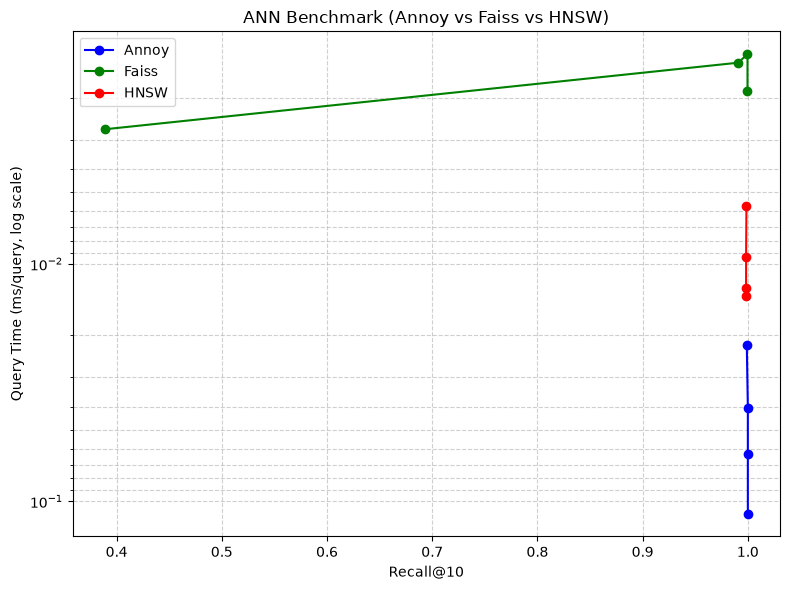

In [5]:
tabel_benchmark = pd.DataFrame(rows)
display(tabel_benchmark)

plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ['blue', 'green', 'red']):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker='o', label=label, color=color)
plt.xlabel('Recall@10')
plt.ylabel('Query Time (ms/query, log scale)')
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('ANN Benchmark (Annoy vs Faiss vs HNSW)')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.tight_layout()
plt.show()